# Projeto 2 - Reinforcement Learning e ambientes não determinísticos

**Integrante:** Marcus Vinicius Aguiar Maia

Este notebook implementa e compara Q-learning e SARSA no ambiente Taxi-v4 do Gymnasium, em cenários determinístico e não determinístico.

O projeto segue o enunciado da disciplina: cinco treinamentos por configuração, registro do reward por episódio, avaliação em 100 execuções e comparação por timesteps, desvio padrão, reward e taxa de sucesso.


## 1. Ambiente e hiperparâmetros

O Taxi-v4 possui 500 estados e 6 ações. O agente recebe -1 por passo, +20 ao entregar corretamente e -10 para pickup/dropoff ilegais.

No ambiente não determinístico usamos is_rainy=True e rainy_probability=0.6.

A meta de reward usada como referência nos gráficos é 8.


In [13]:
from pathlib import Path
import csv
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from rl_taxi import (
    EPISODES,
    ALPHA,
    GAMMA,
    EPSILON_START,
    EPSILON_MIN,
    EPSILON_DECAY,
    MAX_STEPS,
    SEEDS,
    train_many,
    evaluate_qtables,
    summarize_results,
    moving_average,
)

RESULTS_DIR = Path("resultados")
RESULTS_DIR.mkdir(exist_ok=True)

print("Episódios:", EPISODES)
print("Alpha:", ALPHA)
print("Gamma:", GAMMA)
print("Epsilon inicial:", EPSILON_START)
print("Epsilon mínimo:", EPSILON_MIN)
print("Epsilon decay:", EPSILON_DECAY)
print("Máximo de passos:", MAX_STEPS)
print("Seeds:", SEEDS)


Episódios: 10000
Alpha: 0.1
Gamma: 0.95
Epsilon inicial: 1.0
Epsilon mínimo: 0.01
Epsilon decay: 0.9995
Máximo de passos: 200
Seeds: [42, 43, 44, 45, 46]


## 2. Funções auxiliares para resultados e gráficos


In [14]:
def save_rewards(filename, rewards):
    header = ",".join(f"run_{i + 1}" for i in range(rewards.shape[0]))
    np.savetxt(
        RESULTS_DIR / filename,
        rewards.T,
        delimiter=",",
        header=header,
        comments="",
        fmt="%.4f",
    )


def save_evaluations(filename, grouped_results):
    fields = ["condicao", "algoritmo", "q_table", "episode", "timesteps", "reward", "success"]

    with open(RESULTS_DIR / filename, "w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=fields)
        writer.writeheader()

        for condition, algorithm, results in grouped_results:
            for row in results:
                writer.writerow(
                    {
                        "condicao": condition,
                        "algoritmo": algorithm,
                        **row,
                    }
                )


def smoothed_runs(rewards, window=100):
    return np.array([moving_average(run, window) for run in rewards])


def plot_learning(rewards_by_label, title, filename, window=100):
    plt.figure(figsize=(10, 5))

    for label, rewards in rewards_by_label.items():
        smooth = smoothed_runs(rewards, window)
        mean = smooth.mean(axis=0)
        std = smooth.std(axis=0)
        x = np.arange(window, window + len(mean))

        plt.plot(x, mean, label=label)
        plt.fill_between(x, mean - std, mean + std, alpha=0.15)

    plt.axhline(8, linestyle="--", label="Meta de reward (8)")
    plt.title(title)
    plt.xlabel("Episódio")
    plt.ylabel("Reward acumulado")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / filename, dpi=150)
    plt.show()


def first_target_episode(rewards, target=8, window=100):
    mean_curve = rewards.mean(axis=0)
    smooth = moving_average(mean_curve, window)
    indexes = np.where(smooth >= target)[0]
    if len(indexes) == 0:
        return None
    return int(indexes[0] + window)


def markdown_summary(summaries):
    lines = [
        "| Treinamento / avaliação | Timesteps médios | Desvio padrão | Reward médio | Taxa de sucesso |",
        "|---|---:|---:|---:|---:|",
    ]

    for label, summary in summaries.items():
        lines.append(
            f"| {label} | {summary['mean_timesteps']:.2f} | "
            f"{summary['std_timesteps']:.2f} | {summary['mean_reward']:.2f} | "
            f"{summary['success_rate']:.1f}% |"
        )

    display(Markdown("\n".join(lines)))


## 3. Q-learning e SARSA

Q-learning é off-policy e usa o maior valor Q disponível no próximo estado:

Q(s,a) ← Q(s,a) + α [r + γ max Q(s',a') - Q(s,a)]

SARSA é on-policy e atualiza usando a próxima ação escolhida pela própria política epsilon-greedy:

Q(s,a) ← Q(s,a) + α [r + γ Q(s',a') - Q(s,a)]

As implementações estão no arquivo rl_taxi.py.


## 4. Treinamento no ambiente determinístico

Cada algoritmo é treinado cinco vezes, usando as mesmas seeds e os mesmos hiperparâmetros.


In [15]:
q_det_tables, q_det_rewards = train_many("q_learning", rainy=False)
s_det_tables, s_det_rewards = train_many("sarsa", rainy=False)

save_rewards("rewards_qlearning_deterministico.csv", q_det_rewards)
save_rewards("rewards_sarsa_deterministico.csv", s_det_rewards)

print("Treinamento determinístico concluído.")


Treinamento determinístico concluído.


## 5. Curvas de aprendizado no ambiente determinístico


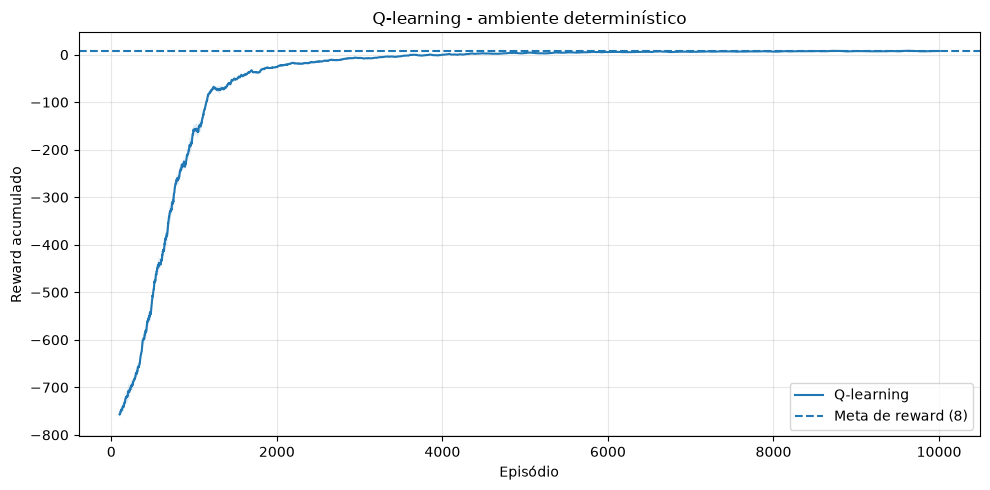

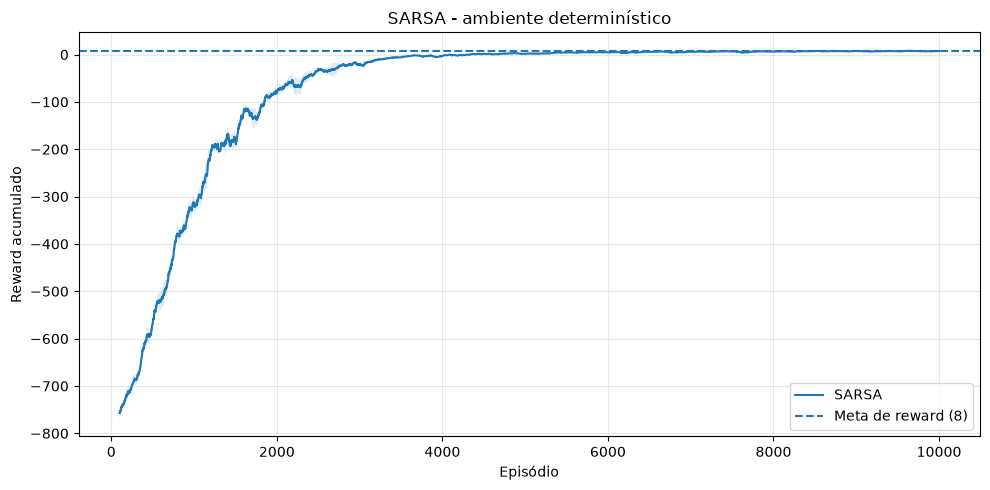

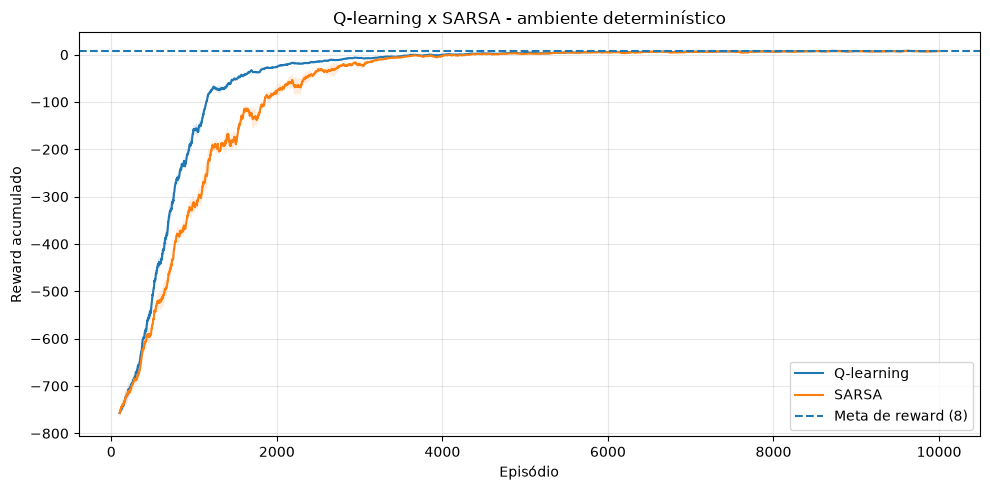

In [16]:
plot_learning(
    {"Q-learning": q_det_rewards},
    "Q-learning - ambiente determinístico",
    "qlearning_deterministico.png",
)

plot_learning(
    {"SARSA": s_det_rewards},
    "SARSA - ambiente determinístico",
    "sarsa_deterministico.png",
)

plot_learning(
    {
        "Q-learning": q_det_rewards,
        "SARSA": s_det_rewards,
    },
    "Q-learning x SARSA - ambiente determinístico",
    "comparacao_deterministico.png",
)


## 6. Avaliação no ambiente determinístico

Cada uma das cinco Q-tables é executada 20 vezes, totalizando 100 episódios de avaliação por algoritmo. Durante a avaliação não existe exploração e a Q-table não é atualizada.


In [17]:
q_det_eval = evaluate_qtables(q_det_tables, rainy=False, episodes_per_table=20)
s_det_eval = evaluate_qtables(s_det_tables, rainy=False, episodes_per_table=20)

q_det_summary = summarize_results(q_det_eval)
s_det_summary = summarize_results(s_det_eval)

summaries = {
    "Q-learning: determinístico → determinístico": q_det_summary,
    "SARSA: determinístico → determinístico": s_det_summary,
}

markdown_summary(summaries)


| Treinamento / avaliação | Timesteps médios | Desvio padrão | Reward médio | Taxa de sucesso |
|---|---:|---:|---:|---:|
| Q-learning: determinístico → determinístico | 13.23 | 2.49 | 7.77 | 100.0% |
| SARSA: determinístico → determinístico | 13.39 | 2.62 | 7.61 | 100.0% |

## 7. Eficiência de aprendizado no ambiente determinístico


In [18]:
q_target = first_target_episode(q_det_rewards)
s_target = first_target_episode(s_det_rewards)

print("Primeiro episódio em que a média móvel alcança reward 8:")
print("Q-learning:", q_target if q_target is not None else "não alcançou")
print("SARSA:", s_target if s_target is not None else "não alcançou")

if q_target is not None and s_target is not None:
    if q_target < s_target:
        print("Q-learning atingiu a meta antes nesta execução.")
    elif s_target < q_target:
        print("SARSA atingiu a meta antes nesta execução.")
    else:
        print("Os dois atingiram a meta no mesmo ponto aproximado.")
else:
    print("A comparação pela meta deve considerar que pelo menos um agente não a alcançou.")


Primeiro episódio em que a média móvel alcança reward 8:
Q-learning: 9616
SARSA: não alcançou
A comparação pela meta deve considerar que pelo menos um agente não a alcançou.


## 8. Q-tables determinísticas executadas no ambiente não determinístico

Nesta etapa não há novo treinamento. As políticas aprendidas no ambiente determinístico são executadas com is_rainy=True e rainy_probability=0.6.


In [19]:
q_det_rain_eval = evaluate_qtables(q_det_tables, rainy=True, episodes_per_table=20)
s_det_rain_eval = evaluate_qtables(s_det_tables, rainy=True, episodes_per_table=20)

q_det_rain_summary = summarize_results(q_det_rain_eval)
s_det_rain_summary = summarize_results(s_det_rain_eval)

summaries.update(
    {
        "Q-learning: determinístico → chuvoso": q_det_rain_summary,
        "SARSA: determinístico → chuvoso": s_det_rain_summary,
    }
)

markdown_summary(
    {
        "Q-learning: determinístico → determinístico": q_det_summary,
        "Q-learning: determinístico → chuvoso": q_det_rain_summary,
        "SARSA: determinístico → determinístico": s_det_summary,
        "SARSA: determinístico → chuvoso": s_det_rain_summary,
    }
)


| Treinamento / avaliação | Timesteps médios | Desvio padrão | Reward médio | Taxa de sucesso |
|---|---:|---:|---:|---:|
| Q-learning: determinístico → determinístico | 13.23 | 2.49 | 7.77 | 100.0% |
| Q-learning: determinístico → chuvoso | 24.75 | 9.30 | -3.75 | 100.0% |
| SARSA: determinístico → determinístico | 13.39 | 2.62 | 7.61 | 100.0% |
| SARSA: determinístico → chuvoso | 25.02 | 9.14 | -4.02 | 100.0% |

### Discussão do impacto do não determinismo

Ao levar as políticas treinadas no ambiente determinístico para o ambiente chuvoso, os dois agentes continuaram com **100% de sucesso**, mas passaram a precisar de aproximadamente o dobro de passos.

- Q-learning: de **13.23** para **24.75** timesteps médios
- SARSA: de **13.39** para **25.02** timesteps médios

O desvio padrão também aumentou de cerca de 2.5 para aproximadamente 9 passos. O reward médio caiu de **7.77 para -3.75** no Q-learning e de **7.61 para -4.02** no SARSA.

Isso acontece porque, no ambiente não determinístico, uma ação de movimento nem sempre leva o táxi para a direção escolhida. A política aprendida continua utilizável, mas passa a gastar mais ações para corrigir desvios causados pela aleatoriedade.



## 9. Treinamento no ambiente não determinístico

Agora Q-learning e SARSA são treinados novamente no próprio ambiente chuvoso, mantendo exatamente os mesmos hiperparâmetros.


In [ ]:
q_rain_tables, q_rain_rewards = train_many("q_learning", rainy=True)
s_rain_tables, s_rain_rewards = train_many("sarsa", rainy=True)

save_rewards("rewards_qlearning_chuvoso.csv", q_rain_rewards)
save_rewards("rewards_sarsa_chuvoso.csv", s_rain_rewards)

print("Treinamento não determinístico concluído.")


## 10. Curvas de aprendizado no ambiente não determinístico


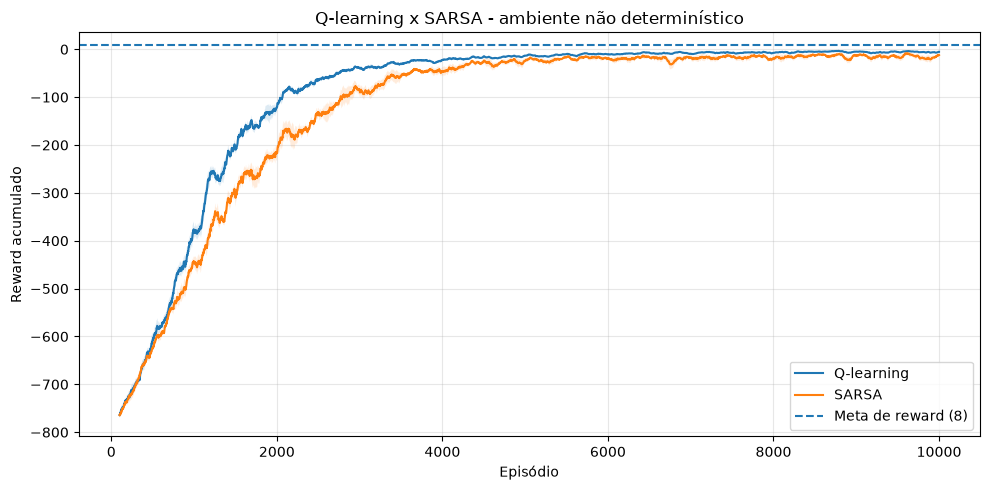

In [ ]:
plot_learning(
    {
        "Q-learning": q_rain_rewards,
        "SARSA": s_rain_rewards,
    },
    "Q-learning x SARSA - ambiente não determinístico",
    "comparacao_chuvoso.png",
)


## 11. Avaliação após treinamento no ambiente não determinístico


In [ ]:
q_rain_eval = evaluate_qtables(q_rain_tables, rainy=True, episodes_per_table=20)
s_rain_eval = evaluate_qtables(s_rain_tables, rainy=True, episodes_per_table=20)

q_rain_summary = summarize_results(q_rain_eval)
s_rain_summary = summarize_results(s_rain_eval)

summaries.update(
    {
        "Q-learning: chuvoso → chuvoso": q_rain_summary,
        "SARSA: chuvoso → chuvoso": s_rain_summary,
    }
)

markdown_summary(summaries)


| Treinamento / avaliação | Timesteps médios | Desvio padrão | Reward médio | Taxa de sucesso |
|---|---:|---:|---:|---:|
| Q-learning: determinístico → determinístico | 13.23 | 2.49 | 7.77 | 100.0% |
| SARSA: determinístico → determinístico | 13.39 | 2.62 | 7.61 | 100.0% |
| Q-learning: determinístico → chuvoso | 24.75 | 9.30 | -3.75 | 100.0% |
| SARSA: determinístico → chuvoso | 25.02 | 9.14 | -4.02 | 100.0% |
| Q-learning: chuvoso → chuvoso | 24.87 | 8.99 | -9.75 | 97.0% |
| SARSA: chuvoso → chuvoso | 29.16 | 17.10 | -13.92 | 97.0% |

## 12. Salvando os resultados das 600 avaliações


In [ ]:
save_evaluations(
    "avaliacao.csv",
    [
        ("determinístico → determinístico", "Q-learning", q_det_eval),
        ("determinístico → determinístico", "SARSA", s_det_eval),
        ("determinístico → chuvoso", "Q-learning", q_det_rain_eval),
        ("determinístico → chuvoso", "SARSA", s_det_rain_eval),
        ("chuvoso → chuvoso", "Q-learning", q_rain_eval),
        ("chuvoso → chuvoso", "SARSA", s_rain_eval),
    ],
)

print("Resultados salvos na pasta resultados/")



Resultados salvos na pasta resultados/


## 13. Comparação final e conclusão


In [ ]:
def compare_value(name, a, b, smaller_is_better=True):
    if np.isclose(a, b):
        return f"{name}: resultados muito próximos ({a:.2f} e {b:.2f})."

    first_better = a < b if smaller_is_better else a > b
    winner = "Q-learning" if first_better else "SARSA"
    return f"{name}: {winner} apresentou o melhor valor nesta execução ({a:.2f} vs {b:.2f})."


display(Markdown("### Ambiente determinístico"))
print(compare_value(
    "Timesteps médios",
    q_det_summary["mean_timesteps"],
    s_det_summary["mean_timesteps"],
))
print(compare_value(
    "Reward médio",
    q_det_summary["mean_reward"],
    s_det_summary["mean_reward"],
    smaller_is_better=False,
))
print(
    f"Taxa de sucesso: Q-learning {q_det_summary['success_rate']:.1f}% | "
    f"SARSA {s_det_summary['success_rate']:.1f}%"
)

display(Markdown("### Política determinística testada no ambiente chuvoso"))
print(
    f"Q-learning: {q_det_summary['mean_timesteps']:.2f} → "
    f"{q_det_rain_summary['mean_timesteps']:.2f} timesteps médios."
)
print(
    f"SARSA: {s_det_summary['mean_timesteps']:.2f} → "
    f"{s_det_rain_summary['mean_timesteps']:.2f} timesteps médios."
)

display(Markdown("### Treinamento no ambiente chuvoso"))
print(compare_value(
    "Timesteps médios",
    q_rain_summary["mean_timesteps"],
    s_rain_summary["mean_timesteps"],
))
print(compare_value(
    "Reward médio",
    q_rain_summary["mean_reward"],
    s_rain_summary["mean_reward"],
    smaller_is_better=False,
))
print(
    f"Taxa de sucesso: Q-learning {q_rain_summary['success_rate']:.1f}% | "
    f"SARSA {s_rain_summary['success_rate']:.1f}%"
)


### Ambiente determinístico

Timesteps médios: Q-learning apresentou o melhor valor nesta execução (13.23 vs 13.39).
Reward médio: Q-learning apresentou o melhor valor nesta execução (7.77 vs 7.61).
Taxa de sucesso: Q-learning 100.0% | SARSA 100.0%


### Política determinística testada no ambiente chuvoso

Q-learning: 13.23 → 24.75 timesteps médios.
SARSA: 13.39 → 25.02 timesteps médios.


### Treinamento no ambiente chuvoso

Timesteps médios: Q-learning apresentou o melhor valor nesta execução (24.87 vs 29.16).
Reward médio: Q-learning apresentou o melhor valor nesta execução (-9.75 vs -13.92).
Taxa de sucesso: Q-learning 97.0% | SARSA 97.0%


### Conclusão

No ambiente determinístico, Q-learning e SARSA apresentaram resultados muito próximos. Os dois atingiram **100% de sucesso**, com pequena vantagem do Q-learning em timesteps médios (**13.23 contra 13.39**) e reward médio (**7.77 contra 7.61**). Na curva de aprendizado, a média móvel do Q-learning alcançou a referência de reward 8 por volta do episódio 9.616, enquanto o SARSA não alcançou essa referência nos 10.000 episódios.

Quando as políticas determinísticas foram executadas no ambiente chuvoso, ambas ainda concluíram 100% das tarefas, porém com aproximadamente **25 timesteps médios** e maior variabilidade. Portanto, a política aprendida no ambiente determinístico continuou eficaz, mas perdeu eficiência diante da aleatoriedade.

No treinamento realizado diretamente no ambiente chuvoso, os dois algoritmos obtiveram **97% de sucesso**. O Q-learning apresentou melhor desempenho final que o SARSA, com **24.87 timesteps médios e reward -9.75**, contra **29.16 timesteps e reward -13.92** do SARSA.

Esses resultados indicam que o não determinismo tornou o aprendizado mais difícil com os mesmos hiperparâmetros e a mesma quantidade de episódios. Nos experimentos realizados, o Q-learning apresentou desempenho ligeiramente superior no ambiente determinístico e uma vantagem mais clara no ambiente chuvoso.

